# Safe authority for AI agents in a coupled city

A city runs critical services (power, water, transport) that are interconnected. The operators of these services are increasingly becoming AI agents that read sensors, message each other, and propose actions. This project seeks to understand:

**How much authority can we give the agents, and how much may they talk, before one small error cascades city‑wide?**

The answer the project builds toward: write a nonnegative matrix $K$ that bounds how deficits propagate in one step; the system is safe iff the spectral radius $\rho(K) < 1$. Authority, communication, and mitigation are knobs that move entries of $K$.

| Section | Adds |
|---|---|
| 1 | The model, $\rho$, and the $2\times2$ condition $ce < (1-p)(1-a)$ |
| 2 | The knobs $(m, z, \gamma)$; a $4\times4$ example that is stable layer‑by‑layer but unstable together |
| 3 | A witness certificate that replaces sweeping over $\gamma$ with one formula |
| 4 | All knobs at once: per-sector $m$, per-link $z$, per-agent $\gamma$ as one LP |


## 0. The model

**Two kinds of coupling:** 
1. Services are *physically* coupled (power drops → pumps slow, signals fail). 
2. Agents are *informationally* coupled (messages).

For each coupling, we track the deficit of each service from normal. For a service sector (e.g. the water network):

$$d^P_i = \frac{\text{normal service} - \text{actual service}}{\text{normal service}}$$

* Delivering 100% of normal → $d^P = 0$ (no problem)
* Delivering 70% of normal → $d^P = 0.3$ (a 30% shortfall)

For an AI agent:

$$d^A_a = \frac{\text{how far its proposed action is from the correct action}}{\text{size of a typical action}}$$

* The agent proposes exactly the right action → $d^A = 0$
* The right move is "open the valve 10%" and it proposes "open it 15%" → it's off by 5 points on a typical 10-point action, so $d^A = 0.5$

Since they both measure gaps from normal function, they can't be negative and both are $\ge 0$ by construction.

This results in **Four matrices**, one per direction a deficit can travel:

| | direction | controlled by |
|---|---|---|
| $P$ | physical → physical (diagonal = persistence) | plant; later mitigation $m$ |
| $A$ | agent → agent via messages | communication $z$ |
| $C$ | agent → physical: **the only way an agent error becomes real** | authority $\gamma$ |
| $D$ | physical → agent: the agent sees a problem and reacts | fixed by deployment |

$$
\begin{bmatrix} d^P_{t+1} \\ d^A_{t+1} \end{bmatrix}
\preceq
\underbrace{\begin{bmatrix} P & C \\ D & A \end{bmatrix}}_{K}
\begin{bmatrix} d^P_{t} \\ d^A_{t} \end{bmatrix} + \xi_t
\qquad (\preceq \text{ entrywise},\ \xi_t \ge 0 \text{ a disturbance})
$$

$C$ and $D$ are the only blocks where the layers touch. Zero either one and $K$ is block‑triangular: $\rho(K) = \max\{\rho(P), \rho(A)\}$ and the layers stop interacting.

**The one fact (Perron–Frobenius).** For $K \ge 0$: $\rho(K) < 1 \Rightarrow d_t \to 0$; $\rho(K) > 1 \Rightarrow d_t$ can grow without bound. $\rho$ is the per‑step growth factor of the worst‑case deficit profile, so the whole safety question is one number.

In the simplest case (one sector, one agent) each block is a single number, so $K$ becomes

$$M = \begin{bmatrix} p & c \\ e & a \end{bmatrix}$$

- $p$: how much of a sector's shortfall persists to the next step
- $a$: how much of an agent's error persists to its next proposal
- $c$ (authority): how much shortfall an agent's error creates
- $e$ (sensing): how much agent error a shortfall creates

For a $2\times2$ matrix $\begin{bmatrix} p & c \\ e & a \end{bmatrix}$ the eigenvalues are $\lambda = \tfrac12\big[(p+a) \pm \sqrt{(p+a)^2 - 4(pa-ce)}\big]$, and for $p, a < 1$:

$$\boxed{\;\rho < 1 \iff c\,e < (1-p)(1-a)\;}$$

Left: authority × sensing, the gain of one trip around the loop. Right: the two layers' stability margins. **Safety is a product — it cannot be bought in one layer alone.**


In [1]:
%pip install matplotlib numpy ipywidgets
%pip install scipy

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def rho(M):
    return float(np.max(np.abs(np.linalg.eigvals(np.asarray(M, float)))))

def iterate(M, d0, steps):
    d, out = np.asarray(d0, float), []
    for _ in range(steps + 1):
        out.append(d); d = M @ d
    return np.array(out)

def coupling_diagram(p, a, c, e, ax):
    """Two layers, four arrows; arrow width = gain."""
    ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
    for y, lbl, col in [(4.2, "agents  $d^A$", "#dbe9f6"), (0.6, "sectors  $d^P$", "#fde6c4")]:
        ax.add_patch(FancyBboxPatch((3, y), 4, 1.2, boxstyle="round,pad=0.15", fc=col, ec="k"))
        ax.text(5, y + 0.6, lbl, ha="center", va="center", fontsize=11)
    w = lambda g: 1 + 6*g
    arr = lambda s, t, g, col, **k: ax.add_patch(FancyArrowPatch(s, t, arrowstyle="-|>", mutation_scale=15, lw=w(g), color=col, **k))
    arr((7.2, 5.0), (7.2, 4.6), a, "#2a6db2", connectionstyle="arc3,rad=-2.2"); ax.text(8.9, 4.8, f"A = {a:.2f}", color="#2a6db2", ha="center")
    arr((7.2, 1.4), (7.2, 1.0), p, "#c66a00", connectionstyle="arc3,rad=-2.2"); ax.text(8.9, 1.2, f"P = {p:.2f}", color="#c66a00", ha="center")
    arr((4.2, 4.1), (4.2, 1.9), c, "#9b1c1c"); ax.text(2.9, 3.0, f"C = {c:.2f}\nauthority", color="#9b1c1c", ha="center")
    arr((5.8, 1.9), (5.8, 4.1), e, "#2e7d32"); ax.text(7.1, 3.0, f"D = {e:.2f}\nsensing", color="#2e7d32", ha="center")


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 80.4 kB/s  0:04:42m0:00:0100:07

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Two-layer model

The two-layer model inccludes one sector and one agent, with the layers equally persistent ($p = a = 0.6$). In this simulation, we vary how strongly the layers are coupled, through authority $c$ and sensing $e$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

GREEN, RED, BLUE, ORANGE = "#2e7d32", "#9b1c1c", "#2a6db2", "#c66a00"
rho = lambda M: max(abs(np.linalg.eigvals(np.asarray(M, float))))

def iterate(M, d0, steps=15):
    d, out = np.asarray(d0, float), []
    for _ in range(steps + 1):
        out.append(d); d = M @ d
    return np.array(out)

def draw_loop(ax, p, a, c, e):
    ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
    for y, lbl, col in [(4.2, "agents  $d^A$", "#dbe9f6"), (0.6, "sectors  $d^P$", "#fde6c4")]:
        ax.add_patch(FancyBboxPatch((3, y), 4, 1.2, boxstyle="round,pad=0.15", fc=col, ec="k"))
        ax.text(5, y + .6, lbl, ha="center", va="center", fontsize=11)
    arr = lambda s, t, g, col, **k: ax.add_patch(FancyArrowPatch(s, t, arrowstyle="-|>", mutation_scale=15, lw=1 + 6*g, color=col, **k))
    loop = dict(connectionstyle="arc3,rad=-2.2")
    arr((7.2, 5.0), (7.2, 4.6), a, BLUE, **loop);   ax.text(8.9, 4.8, f"A = {a:.2f}", color=BLUE, ha="center")
    arr((7.2, 1.4), (7.2, 1.0), p, ORANGE, **loop); ax.text(8.9, 1.2, f"P = {p:.2f}", color=ORANGE, ha="center")
    arr((4.2, 4.1), (4.2, 1.9), c, RED);   ax.text(2.7, 3.0, f"C = {c:.2f}\nauthority", color=RED, ha="center")
    arr((5.8, 1.9), (5.8, 4.1), e, GREEN); ax.text(7.3, 3.0, f"D = {e:.2f}\nsensing", color=GREEN, ha="center")

def dashboard(p, a, c, e):
    M = np.array([[p, c], [e, a]]); r = rho(M); ok = r < 1
    margin = (1 - p)*(1 - a)
    fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[1.1, 1, 1.2]))

    draw_loop(ax0, p, a, c, e)
    ax0.set_title(f"ρ = {r:.3f}  →  {'stable' if ok else 'unstable'}", color=GREEN if ok else RED, fontweight="bold")

    g = np.linspace(0.005, 1.2, 300)
    ax1.fill_between(g, 0, np.minimum(margin/g, 1.2), color=GREEN, alpha=.15)
    ax1.plot(g, margin/g, "k")
    ax1.plot(c, e, "o", ms=11, color=GREEN if ok else RED)
    if e > 0: ax1.axvline(margin/e, color="gray", ls=":", lw=1); ax1.text(margin/e, 1.13, f" c* = {margin/e:.2f}", fontsize=9)
    ax1.set_xlim(0, 1.2); ax1.set_ylim(0, 1.2)
    ax1.set_xlabel("c  (authority)"); ax1.set_ylabel("e  (sensing)")
    ax1.set_title(f"ce = {c*e:.3f}   vs   (1-p)(1-a) = {margin:.3f}")

    traj = iterate(M, [0.1, 0])
    ax2.plot(traj[:, 0], "o-", color=ORANGE, label="sector deficit $d^P$")
    ax2.plot(traj[:, 1], "s-", color=BLUE, label="agent error $d^A$")
    ax2.set_xlabel("step"); ax2.set_ylabel("deficit"); ax2.grid(alpha=.3); ax2.legend(loc="upper left")
    ax2.set_title("response to a 10% sector shortfall")
    plt.tight_layout(); plt.show()

PRESETS = {"Weak coupling":            (0.6, 0.6, 0.30, 0.3),
           "Moderate coupling":        (0.6, 0.6, 0.50, 0.5),
           "Max safe authority":       (0.6, 0.6, 0.32, 0.5),
           "Backup capacity (p=0.4)":  (0.4, 0.6, 0.48, 0.5)}

try:
    import ipywidgets as w
    from IPython.display import display
    S = lambda v, hi, d: w.FloatSlider(value=v, min=0, max=hi, step=.01, description=d, continuous_update=False)
    sl = dict(p=S(.6, .95, "p  physics"), a=S(.6, .95, "a  messages"), c=S(.5, 1.2, "c  authority"), e=S(.5, 1.2, "e  sensing"))
    preset = w.Dropdown(options=["(custom)"] + list(PRESETS), description="preset")
    def apply(ch):
        if ch["new"] in PRESETS:
            for k, v in zip("pace", PRESETS[ch["new"]]): sl[k].value = v
    preset.observe(apply, names="value")
    display(w.VBox([preset, w.HBox([sl["p"], sl["a"]]), w.HBox([sl["c"], sl["e"]])]),
            w.interactive_output(dashboard, sl))
except ImportError:
    dashboard(*PRESETS["Moderate coupling"])

Output()

### Findings

**1. Coupling alone can destabilize two stable layers.**

*Evidence:* with $p = a = 0.6$, each layer alone has $\rho = 0.6$. At $c = e = 0.3$, $\rho(M) = 0.90$ and a 10% shortfall decays (total $0.1 \to 0.0729$ in three steps). At $c = e = 0.5$, $\rho(M) = 1.10$ and the same shortfall grows without bound. Nothing inside either layer changed; only the cross-couplings $c$ and $e$ did.

*Implication:* if $C$ or $D$ were zero, $K$ would be block-triangular and $\rho(K) = \max\{\rho(P), \rho(A)\}$, so each layer could be certified on its own. With both nonzero, $\rho(K)$ can exceed both. Certifying the grid and the agents separately is therefore not enough. Safety has to be assessed on $K$ as a whole.

**2. The maximum safe authority $c^*$ is set by $p$, $a$ and $e$.**

*Evidence:* solving $ce < (1-p)(1-a)$ for authority gives $c^* = (1-p)(1-a)/e$. With $p = a = 0.6$ and $e = 0.5$, $c^* = 8/25 = 0.32$. Check: $\rho = 1.000$ at $c = 0.32$ and $\rho \approx 1.006$ at $c = 0.33$. Lowering $p$ from 0.6 to 0.4 (backup capacity) raises $c^*$ to $12/25 = 0.48$, a gain of $4/25$. When $p = a$, $\rho = p + \sqrt{ce}$, so the system is safe exactly when $\sqrt{ce} < 1 - p$.

*Implication:* the left side $ce$ is the gain of one trip around the loop; the right side $(1-p)(1-a)$ is the product of the two layers' margins. Because safety is a product, it can't be bought in one layer alone, but it can be traded between layers: reducing how long shortfalls persist ($p$) directly raises how much authority ($c$) the agents can safely hold.

### Where this leaves us

- Safe iff $\rho(K) < 1$; in the two-layer case, iff $ce < (1-p)(1-a)$.
- Two individually stable layers can be jointly unstable, and the instability lives in the product of the cross-couplings $c$ and $e$.

**Open:** the numbers were assumed. In reality $P$, $A$ and $C$ are shaped by design choices (mitigation $m$, communication $z$, authority $\gamma$), and only $D$ is fixed. The next section makes those knobs explicit and finds $c^*$ on a realistic multi-sector example.

---

case                          p    a     c    e      ce  (1-p)(1-a)       ρ   verdict
Weak coupling               0.6  0.6   0.3  0.3   0.090       0.160   0.900   stable
Moderate coupling           0.6  0.6   0.5  0.5   0.250       0.160   1.100   unstable
Max safe authority          0.6  0.6  0.32  0.5   0.160       0.160   1.000   boundary
Backup capacity (p=0.4)     0.4  0.6  0.48  0.5   0.240       0.240   1.000   boundary


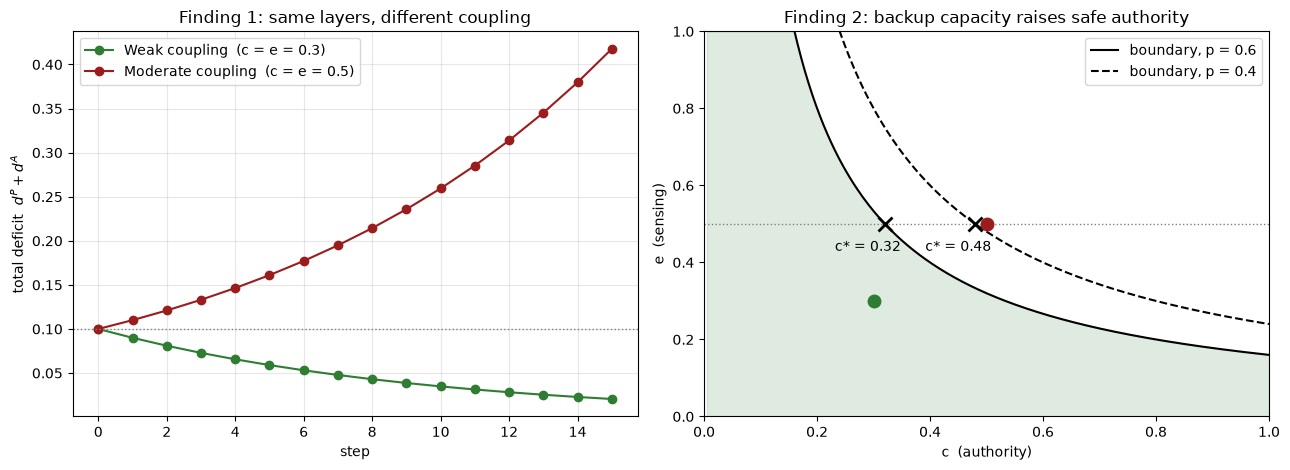

In [3]:
cases = [("Weak coupling",           0.6, 0.6, 0.30, 0.3),
         ("Moderate coupling",       0.6, 0.6, 0.50, 0.5),
         ("Max safe authority",      0.6, 0.6, 0.32, 0.5),
         ("Backup capacity (p=0.4)", 0.4, 0.6, 0.48, 0.5)]

# Table
print(f"{'case':<26}{'p':>5}{'a':>5}{'c':>6}{'e':>5}{'ce':>8}{'(1-p)(1-a)':>12}{'ρ':>8}   verdict")
for name, p, a, c, e in cases:
    r = rho([[p, c], [e, a]])
    print(f"{name:<26}{p:>5}{a:>5}{c:>6}{e:>5}{c*e:>8.3f}{(1-p)*(1-a):>12.3f}{r:>8.3f}   "
          f"{'stable' if r < 1 - 1e-9 else 'boundary' if abs(r-1) < 1e-9 else 'unstable'}")

# Figures
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for (name, p, a, c, e), col in zip(cases[:2], [GREEN, RED]):
    traj = iterate(np.array([[p, c], [e, a]]), [0.1, 0])
    ax1.plot(traj.sum(1), "o-", color=col, label=f"{name}  (c = e = {c})")
ax1.axhline(0.1, color="gray", ls=":", lw=1)
ax1.set_xlabel("step"); ax1.set_ylabel("total deficit  $d^P + d^A$"); ax1.grid(alpha=.3); ax1.legend()
ax1.set_title("Finding 1: same layers, different coupling")

g = np.linspace(0.005, 1, 300)
for p, ls in [(0.6, "-"), (0.4, "--")]:
    ax2.plot(g, (1 - p)*0.4/g, "k", ls=ls, label=f"boundary, p = {p}")
ax2.fill_between(g, 0, np.minimum(0.16/g, 1), color=GREEN, alpha=.15)
ax2.axhline(0.5, color="gray", ls=":", lw=1)
for p in [0.6, 0.4]:
    cs = (1 - p)*0.4/0.5
    ax2.plot(cs, 0.5, "kx", ms=10, mew=2); ax2.annotate(f"c* = {cs:.2f}", (cs, .5), (cs - .03, .43), ha="center")
ax2.plot(.3, .3, "o", color=GREEN, ms=9); ax2.plot(.5, .5, "o", color=RED, ms=9)
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1); ax2.legend(loc="upper right")
ax2.set_xlabel("c  (authority)"); ax2.set_ylabel("e  (sensing)")
ax2.set_title("Finding 2: backup capacity raises safe authority")
plt.tight_layout(); plt.show()

## 2. The design knobs

In Section 1 the matrices were fixed numbers. However, in practice, three of the four blocks depend on decisions as $y = (m, z, \gamma)$:

| Knob | What it is | Where it enters | Effect |
|---|---|---|---|
| $m \in [0,1]$ | **Mitigation**: backup capacity, spare generators, extra pumps | $P(m) = (1 - 0.6\,m)\,P_0$ | Shrinks the physical block. $m = 1$ cuts every physical gain by 60%. Costs money. |
| $z \in [0,1]$ | **Communication**: how much one agent listens to another | Off-diagonal entries of $A$: $\;A(z) = \begin{bmatrix} 0.3 & 0.5z \\ 0.5z & 0.3 \end{bmatrix}$ | $z = 0$ cuts every message link, but the diagonal 0.3 (an agent's own error persisting) stays. |
| $\gamma \in [0,1]$ | **Authority**: how much of an agent's proposal is actually executed | $C(\gamma) = \gamma\,C_0$ | $\gamma = 0$: agents are advisory only and $C = 0$. $\gamma = 1$: agents effectively control the plant. |

$D$ (sensing) is not a knob. Agents observe the plant, and since this is more "passive", this doesn't pose a risk.

The model becomes

$$
\begin{bmatrix} d^P_{t+1} \\ d^A_{t+1} \end{bmatrix}
\preceq
\underbrace{\begin{bmatrix} P(m) & C(\gamma) \\ D & A(z) \end{bmatrix}}_{K(y)}
\begin{bmatrix} d^P_{t} \\ d^A_{t} \end{bmatrix} + \xi_t
$$

and the design problem is: choose the cheapest $y$ such that $\rho(K(y)) < 1$.

**Loop gain.** One trip around the loop is

$$G = (I - A)^{-1}\, D\, (I - P)^{-1}\, C$$

Read right to left: an agent error reaches the plant through authority ($C$), spreads through the physics ($(I-P)^{-1}$), is sensed as new agent error ($D$), and spreads through messages ($(I-A)^{-1}$). This is the $4\times4$ version of $ce$ versus $(1-p)(1-a)$ from Section 1.

**The toy city.** Two sectors (power, transport) and two agents (one per sector). Unlike Section 1, the physical block is asymmetric:

$$P_0 = \begin{bmatrix} 0.45 & 0.20 \\ 0.30 & 0.40 \end{bmatrix}, \quad
C_0 = \begin{bmatrix} 0.384 & 0.144 \\ 0.144 & 0.384 \end{bmatrix}, \quad
D = \begin{bmatrix} 0.36 & 0.12 \\ 0.12 & 0.36 \end{bmatrix}$$

In [4]:
import numpy as np
import matplotlib.pyplot as plt

GREEN, RED, BLUE, ORANGE, GRAY = "#2e7d32", "#9b1c1c", "#2a6db2", "#c66a00", "#777777"
rho = lambda M: max(abs(np.linalg.eigvals(np.asarray(M, float))))
I2 = np.eye(2)

# Toy city: sectors (power, transport), agents (power agent, transport agent). Numbers from the Week 2 handout.
P0 = np.array([[0.45, 0.20], [0.30, 0.40]])
C0 = np.array([[0.384, 0.144], [0.144, 0.384]])
D  = np.array([[0.36, 0.12], [0.12, 0.36]])
KAPPA = 0.6

def blocks(m, z, g):
    P = (1 - KAPPA*m) * P0                           # mitigation shrinks physics
    A = np.array([[0.30, 0.50*z], [0.50*z, 0.30]])   # communication scales off-diagonals only
    C = C0 * g                                       # authority scales the agent -> plant block
    return P, A, C, D

def K_of(m, z, g):
    P, A, C, D = blocks(m, z, g)
    return np.block([[P, C], [D, A]])

def G_of(m, z, g):
    """Loop gain: authority -> physics -> sensing -> messages."""
    P, A, C, D = blocks(m, z, g)
    return np.linalg.inv(I2 - A) @ D @ np.linalg.inv(I2 - P) @ C

def tipping_gamma(m, z, tol=1e-6):
    """Largest gamma with rho(K) < 1 (bisection). None if safe even at gamma = 1."""
    if rho(K_of(m, z, 1)) < 1: return None
    lo, hi = 0.0, 1.0
    while hi - lo > tol:
        mid = (lo + hi)/2
        lo, hi = (mid, hi) if rho(K_of(m, z, mid)) < 1 else (lo, mid)
    return lo

def cascade(K, steps=30):
    """Week 2 Part C: 5% power shortfall, constant 0.01 disturbance on each sector."""
    d, xi, out = np.array([0.05, 0, 0, 0]), np.array([0.01, 0.01, 0, 0]), []
    for _ in range(steps + 1):
        out.append(d.sum()); d = K @ d + xi
    return np.array(out)

def dashboard(m, z, g):
    P, A, C, _ = blocks(m, z, g)
    K, rK = K_of(m, z, g), rho(K_of(m, z, g))
    ok = rK < 1
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))

    # (1) the matrix K
    a = ax[0, 0]
    a.imshow(K, cmap="Blues", vmin=0, vmax=0.6)
    for i in range(4):
        for j in range(4):
            a.text(j, i, f"{K[i, j]:.2f}", ha="center", va="center", fontsize=11,
                   color="white" if K[i, j] > 0.4 else "black")
    a.axhline(1.5, color="k", lw=2); a.axvline(1.5, color="k", lw=2)
    for (x, y, s, col) in [(0.5, -0.75, "P(m)", ORANGE), (2.5, -0.75, "C(γ)", RED),
                           (-1.75, 2.55, "D", GREEN), (-0.95, 0.5, "", None)]:
        if s: a.text(x, y, s, ha="center", fontsize=12, color=col, fontweight="bold")
    a.text(2.5, 4.05, "A(z)", ha="center", fontsize=12, color=BLUE, fontweight="bold")
    lbl = ["power", "transport", "power agt", "transp agt"]
    a.set_xticks(range(4)); a.set_xticklabels(lbl, fontsize=8); a.set_yticks(range(4)); a.set_yticklabels(lbl, fontsize=8)
    a.set_title("K(y): one-step propagation bound", pad=34)

    # (2) the four spectral radii
    a = ax[0, 1]
    names = ["ρ(P)\nplant alone", "ρ(A)\nagents alone", "ρ(K)\ntogether", "ρ(G)\none loop"]
    vals = [rho(P), rho(A), rK, rho(G_of(m, z, g))]
    bars = a.bar(names, vals, color=[ORANGE, BLUE, GREEN if ok else RED, GRAY])
    a.axhline(1, color="k", ls="--", lw=1)
    for b, v in zip(bars, vals): a.text(b.get_x() + b.get_width()/2, v + 0.05, f"{v:.3f}", ha="center")
    a.set_ylim(0, max(4, max(vals) + 0.4))
    a.set_title(f"ρ(K) = {rK:.3f}  →  {'stable' if ok else 'unstable'}", color=GREEN if ok else RED, fontweight="bold")

    # (3) rho(K) as authority varies, current setting marked
    a = ax[1, 0]
    gs = np.linspace(0, 1, 201)
    a.plot(gs, [rho(K_of(m, z, x)) for x in gs], "k")
    a.axhspan(0, 1, color=GREEN, alpha=.1); a.axhline(1, color="k", ls="--", lw=1)
    a.plot(g, rK, "o", ms=11, color=GREEN if ok else RED)
    gt = tipping_gamma(m, z)
    if gt is not None:
        a.axvline(gt, color=GRAY, ls=":"); a.text(gt + .01, 0.55, f"γ* = {gt:.3f}", color=GRAY)
    else:
        a.text(0.02, 0.55, "safe at every γ", color=GREEN)
    a.set_xlim(0, 1); a.set_ylim(0.5, 1.5)
    a.set_xlabel("γ  (authority)"); a.set_ylabel("ρ(K)")
    a.set_title(f"where does it tip over?  (m = {m:.2f}, z = {z:.2f})")

    # (4) the cascade
    a = ax[1, 1]
    a.semilogy(cascade(K), "o-", ms=4, color=GREEN if ok else RED)
    a.set_xlabel("step"); a.set_ylabel("total deficit (log scale)"); a.grid(alpha=.3, which="both")
    a.set_title("5% power shortfall + tiny constant disturbance")
    plt.tight_layout(); plt.show()

PRESETS2 = {"Most permissive (m=0, z=1, γ=1)": (0, 1, 1),
            "Authority off (γ=0)":             (0, 1, 0),
            "No communication (z=0)":          (0, 0, 1),
            "Mitigation (m=0.5)":              (0.5, 1, 1),
            "Target γ=0.5, z=0":               (0, 0, 0.5)}

try:
    import ipywidgets as w
    from IPython.display import display
    S = lambda v, d: w.FloatSlider(value=v, min=0, max=1, step=.01, description=d, continuous_update=False)
    sl2 = dict(m=S(0, "m  mitigation"), z=S(1, "z  communication"), g=S(1, "γ  authority"))
    preset2 = w.Dropdown(options=["(custom)"] + list(PRESETS2), description="preset", layout=w.Layout(width="400px"))
    def apply2(ch):
        if ch["new"] in PRESETS2:
            for k, v in zip("mzg", PRESETS2[ch["new"]]): sl2[k].value = v
    preset2.observe(apply2, names="value")
    display(w.VBox([preset2, w.HBox(list(sl2.values()))]), w.interactive_output(dashboard, sl2))
except ImportError:
    dashboard(0, 1, 1)

Output()

### Findings

**1. The Section 1 result holds with realistic, asymmetric numbers.**

*Evidence:* at the most permissive setting ($m = 0$, $z = 1$, $\gamma = 1$), the plant alone has $\rho(P) = 0.671$ and the agents alone have $\rho(A) = 0.800$. Both would pass a separate certification. Together, $\rho(K) = 1.244$. A 5% power shortfall with a tiny constant disturbance grows to a total deficit of 86 in 30 steps. One trip around the loop multiplies an error by $\rho(G) = 3.87$.

*Implication:* this is the $4\times4$ version of $\rho = 1.1$ from $p = a = 0.6$, $c = e = 0.5$. The mechanism is the same: no component failed, and the instability comes from the loop through $C$ and $D$. As a check, at $\gamma = 0$, $C = 0$, $K$ is block-triangular and $\rho(K) = 0.800 = \max\{\rho(P), \rho(A)\}$, exactly as predicted.

**2. Cutting communication is not enough on its own.**

*Evidence:* with $z = 0$, $\rho(A)$ drops from 0.800 to 0.300 but does not reach zero, because the diagonal 0.3 is not a message link. The tipping authority rises from $\gamma^* = 0.258$ to $0.905$, so the system is safe at $\gamma = 0.5$. But at full authority $\rho(K) = 1.023$, still unstable. In the loop gain, only the messages factor $(I - A)^{-1}$ changed; $C$, $D$ and $(I - P)^{-1}$ did not.

*Implication:* [Your Exercise 1(d) sentence: "Limiting communication alone is not sufficient because ___."]



**3. Mitigation buys authority at a nearly constant rate.**

*Evidence:* mitigation scales $P$ by $(1 - 0.6m)$. Tipping $\gamma^*$ rises 0.258 → 0.338 → 0.417 → 0.497 for $m = 0, 0.25, 0.5, 0.75$, about 0.08 per 0.25 of $m$. Across $m \in [0, 1]$ the curve is within 0.0002 of a straight line.

**Why sweeping won't scale.** The tipping points above were found by searching over $\gamma$ with everything else fixed. That works with one variable. A real deployment has a mitigation level per component, a $z$ per message link, and a $\gamma$ per agent per actuator: hundreds of variables, and $\rho(K)$ is a non-smooth function of all of them at once. The next section replaces the sweep with a number computed directly.

---

scenario                  m   z   γ     ρ(P)     ρ(A)     ρ(K)     ρ(G)  tipping γ*
Most permissive           0   1   1   0.6712   0.8000   1.2440   3.8716       0.258
Authority off (γ=0)       0   1   0   0.6712   0.8000   0.8000   0.0000       0.258
No communication          0   0   1   0.6712   0.3000   1.0231   1.1055       0.905
Mitigation m=0.25      0.25   1   1   0.5705   0.8000   1.2023   2.9616       0.338
Mitigation m=0.5        0.5   1   1   0.4699   0.8000   1.1653   2.3974       0.417
Mitigation m=0.75      0.75   1   1   0.3692   0.8000   1.1326   2.0134       0.497


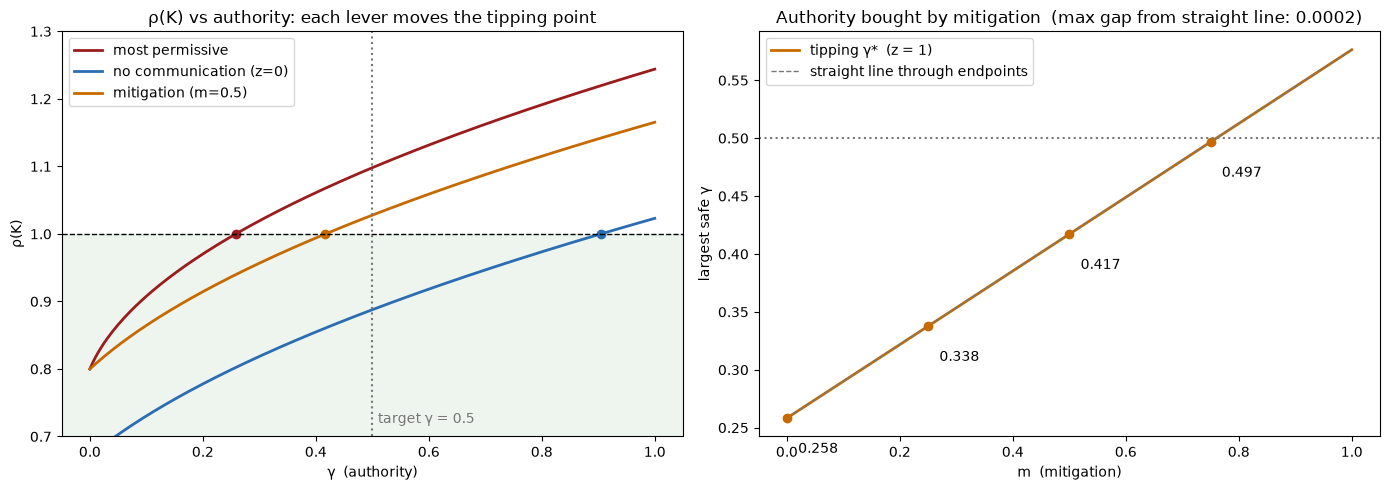

In [5]:
scenarios = [("Most permissive",       0,    1, 1),
             ("Authority off (γ=0)",   0,    1, 0),
             ("No communication",      0,    0, 1),
             ("Mitigation m=0.25",     0.25, 1, 1),
             ("Mitigation m=0.5",      0.5,  1, 1),
             ("Mitigation m=0.75",     0.75, 1, 1)]

# Table
print(f"{'scenario':<22}{'m':>5}{'z':>4}{'γ':>4}{'ρ(P)':>9}{'ρ(A)':>9}{'ρ(K)':>9}{'ρ(G)':>9}{'tipping γ*':>12}")
for name, m, z, g in scenarios:
    P, A, _, _ = blocks(m, z, g)
    gt = tipping_gamma(m, z)
    print(f"{name:<22}{m:>5}{z:>4}{g:>4}{rho(P):>9.4f}{rho(A):>9.4f}{rho(K_of(m, z, g)):>9.4f}"
          f"{rho(G_of(m, z, g)):>9.4f}{'none' if gt is None else f'{gt:.3f}':>12}")

# Figures
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
gs = np.linspace(0, 1, 201)
for (name, m, z), col in zip([("most permissive", 0, 1), ("no communication (z=0)", 0, 0), ("mitigation (m=0.5)", 0.5, 1)],
                             [RED, BLUE, ORANGE]):
    ax1.plot(gs, [rho(K_of(m, z, x)) for x in gs], color=col, lw=2, label=name)
    gt = tipping_gamma(m, z); ax1.plot(gt, 1, "o", color=col)
ax1.axhline(1, color="k", ls="--", lw=1); ax1.axhspan(0, 1, color=GREEN, alpha=.08)
ax1.axvline(0.5, color=GRAY, ls=":"); ax1.text(0.51, 0.72, "target γ = 0.5", color=GRAY)
ax1.set_xlabel("γ  (authority)"); ax1.set_ylabel("ρ(K)"); ax1.set_ylim(0.7, 1.3); ax1.legend()
ax1.set_title("ρ(K) vs authority: each lever moves the tipping point")

ms = np.linspace(0, 1, 41)
gt_m = [tipping_gamma(m, 1) for m in ms]
ax2.plot(ms, gt_m, color=ORANGE, lw=2, label="tipping γ*  (z = 1)")
ax2.plot([0, 1], [gt_m[0], gt_m[-1]], color=GRAY, ls="--", lw=1, label="straight line through endpoints")
for m in [0, 0.25, 0.5, 0.75]:
    gt = tipping_gamma(m, 1); ax2.plot(m, gt, "o", color=ORANGE); ax2.annotate(f"{gt:.3f}", (m, gt), (m + .02, gt - .03))
ax2.axhline(0.5, color=GRAY, ls=":")
ax2.set_xlabel("m  (mitigation)"); ax2.set_ylabel("largest safe γ"); ax2.legend(loc="upper left")
gap = max(abs(np.array(gt_m) - np.interp(ms, [0, 1], [gt_m[0], gt_m[-1]])))
ax2.set_title(f"Authority bought by mitigation  (max gap from straight line: {gap:.4f})")
plt.tight_layout(); plt.show()

## 3. Replacing sweep with a witness certificate

Section 2 found the safe authority level by searching over $\gamma$ which will not scale well since a real design has hundreds of variables. $\rho(K)$ is a non-smooth function of all of them, so we can neither grid-search nor differentiate. We need a test that is **linear** in the design variables.

**The witness.** For $K \ge 0$: if some vector $v > 0$ satisfies

$$K v \preceq \bar\alpha\, v \quad\text{(entrywise)}$$

then $\rho(K) \le \bar\alpha$. The vector $v$ is called a *witness*: it certifies that $K$ contracts. The condition is one inequality per row:

$$\text{row } i: \quad \sum_j K_{ij} v_j \le \bar\alpha\, v_i$$

Once $v$ is fixed, every block of $K$ is linear in $(m, z, \gamma)$, so every row is a linear inequality. A global spectral condition has become a list of linear constraints.

**The trade-off.** A witness proves $\rho \le \bar\alpha$, but failing to find one doesn't prove $\rho > \bar\alpha$. So the certificate is **safe but possibly pessimistic**: it may refuse authority that was actually fine, and it can never grant authority that isn't.

**Each row is a budget.** Build $v$ at the authority-off design $K_0$ (using $v = (\bar\alpha I - K_0)^{-1}\mathbf{1}$, which is always positive). Then each row has:

- **budget:** $\bar\alpha$, the target contraction level (here $0.94$, a small buffer below 1)
- **already spent:** $(K_0 v)_i / v_i$, consumed by physics, sensing and messages before any authority is granted
- **cost per unit of authority:** $(\Delta C\, v)_i / v_i$

The largest authority every row can afford is

$$\gamma^\star = \min_{i} \frac{\bar\alpha\, v_i - (K_0 v)_i}{(\Delta C\, v)_i}$$

This is one minimum over rows, with no sweep, however many rows there are.

In [6]:
# Uses K_of, rho, cascade and the colours from Section 2.
ROWS = ["P0 power", "P1 transport", "A0 power agt", "A1 transp agt"]

def perron(K):
    w, V = np.linalg.eig(K)
    return np.abs(V[:, np.argmax(np.abs(w))].real)

def witness(kind, m, z, a_bar):
    if kind == "resolvent at γ=0":  v = np.linalg.solve(a_bar*np.eye(4) - K_of(m, z, 0), np.ones(4))
    elif kind == "all ones":        v = np.ones(4)
    else:                           v = perron(K_of(m, z, 1))          # Perron vector at γ = 1
    return v / v.max()

def certificate(m, z, v, a_bar):
    """Row budgets for K(γ) v ≤ a_bar v. Returns (γ*, spent, cost, binding row)."""
    K0, dC = K_of(m, z, 0), K_of(m, z, 1) - K_of(m, z, 0)
    spent, cost = K0 @ v / v, dC @ v / v
    room = a_bar - spent
    if (room < 0).any(): return None, spent, cost, None             # over budget before any authority
    rows = np.where(cost > 0)[0]
    ratios = room[rows] / cost[rows]
    return ratios.min(), spent, cost, rows[np.argmin(ratios)]

def true_tip(m, z, a_bar, tol=1e-6):
    """Largest γ with ρ(K) < a_bar, by bisection (the sweep we are replacing)."""
    if rho(K_of(m, z, 1)) < a_bar: return 1.0
    lo, hi = 0.0, 1.0
    while hi - lo > tol:
        mid = (lo + hi)/2
        lo, hi = (mid, hi) if rho(K_of(m, z, mid)) < a_bar else (lo, mid)
    return lo

def dashboard3(m, z, a_bar, g_req, kind):
    v = witness(kind, m, z, a_bar)
    gs, spent, cost, b = certificate(m, z, v, a_bar)
    tip = true_tip(m, z, a_bar)
    g_grant = 0.0 if gs is None else min(g_req, gs)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))

    # (1) the safety account, one row at a time
    a = ax[0]; y = np.arange(4)[::-1]
    a.barh(y, spent, color=GRAY, label="already spent at γ = 0")
    a.barh(y, cost*g_req, left=spent, color=RED, alpha=.8, label=f"withdrawn by requested γ = {g_req:.2f}")
    a.axvline(a_bar, color="k", ls="--"); a.text(a_bar, 4.0, f" ᾱ = {a_bar:.2f}", va="center")
    for yi, s, c in zip(y, spent, cost):
        a.text(0.01, yi, f"spent {s:.3f}   cost/unit γ {c:.2f}", va="center", fontsize=8, color="white")
    a.set_yticks(y); a.set_yticklabels(ROWS); a.set_xlim(0, max(1.5, (spent + cost*g_req).max() + .1))
    a.set_ylim(-0.6, 4.4); a.legend(loc="lower right", fontsize=8)
    title = ("no γ certifiable: a row is over budget at γ = 0" if gs is None
             else f"certificate: γ* = {gs:.4f}   (binding row {ROWS[b].split()[0]})")
    a.set_title(title, color=RED if gs is None else GREEN, fontweight="bold")

    # (2) certified vs truly safe authority
    a = ax[1]; grid = np.linspace(0, 1, 201)
    a.plot(grid, [rho(K_of(m, z, x)) for x in grid], "k")
    a.axhline(a_bar, color="k", ls="--", lw=1)
    a.axvspan(0, tip, color=GREEN, alpha=.12, label=f"truly safe   γ < {tip:.3f}")
    if gs is not None: a.axvspan(0, gs, color=GREEN, alpha=.35, label=f"certified   γ ≤ {gs:.3f}")
    a.axvline(g_req, color=RED, ls=":", label="requested")
    a.set_xlim(0, 1); a.set_ylim(0.5, 1.4); a.set_xlabel("γ  (authority)"); a.set_ylabel("ρ(K)")
    a.legend(loc="upper left", fontsize=8)
    a.set_title("safe but pessimistic" + ("" if gs is None else f": {tip/gs:.2f}× too cautious"))

    # (3) what refusing means
    a = ax[2]
    a.semilogy(cascade(K_of(m, z, g_req)), "o-", ms=3, color=RED, label=f"requested γ = {g_req:.2f}")
    a.semilogy(cascade(K_of(m, z, g_grant)), "o-", ms=3, color=GREEN, label=f"granted γ = {g_grant:.4f}")
    a.set_xlabel("step"); a.set_ylabel("total deficit (log)"); a.grid(alpha=.3, which="both"); a.legend(fontsize=8)
    a.set_title("same plant, same agents, different γ")
    plt.tight_layout(); plt.show()

PRESETS3 = {"Worked example (resolvent witness)": (0,   1, 0.94, 0.9, "resolvent at γ=0"),
            "Lazy witness (all ones)":            (0,   1, 0.94, 0.9, "all ones"),
            "Perron vector at γ=1":               (0,   1, 0.94, 0.9, "Perron at γ=1"),
            "Mitigation m=0.5":                   (0.5, 1, 0.94, 0.9, "resolvent at γ=0"),
            "No communication z=0":               (0,   0, 0.94, 0.9, "resolvent at γ=0")}

try:
    import ipywidgets as w
    from IPython.display import display
    S = lambda v, lo, hi, d: w.FloatSlider(value=v, min=lo, max=hi, step=.01, description=d, continuous_update=False)
    sl3 = dict(m=S(0, 0, 1, "m  mitigation"), z=S(1, 0, 1, "z  communication"), a_bar=S(.94, .85, .99, "ᾱ  target"),
               g_req=S(.9, 0, 1, "γ requested"),
               kind=w.Dropdown(options=["resolvent at γ=0", "all ones", "Perron at γ=1"], description="witness"))
    preset3 = w.Dropdown(options=["(custom)"] + list(PRESETS3), description="preset", layout=w.Layout(width="420px"))
    def apply3(ch):
        if ch["new"] in PRESETS3:
            for k, val in zip(["m", "z", "a_bar", "g_req", "kind"], PRESETS3[ch["new"]]): sl3[k].value = val
    preset3.observe(apply3, names="value")
    display(w.VBox([preset3, w.HBox([sl3["m"], sl3["z"], sl3["a_bar"]]), w.HBox([sl3["g_req"], sl3["kind"]])]),
            w.interactive_output(dashboard3, sl3))
except ImportError:
    dashboard3(*PRESETS3["Worked example (resolvent witness)"])

Output()

### Findings

**1. One witness replaces the sweep but at a measurable cost in authority.**

*Evidence:* with the witness built at $\gamma = 0$, the closed form gives $\gamma^\star = 0.0948$, with row P1 (transport) binding. This is a valid certificate: at $\gamma^\star$, $\max_i (Kv)_i/v_i = 0.940$ and the true $\rho(K) = 0.904$. The true tipping point for $\bar\alpha = 0.94$ is $0.148$, so the certificate refuses about $1.56\times$ more authority than necessary. Requested $\gamma = 0.9$ gives $\rho = 1.218$ and a deficit of 50.7 at step 30. Granting $\gamma^\star = 0.0948$ gives $\rho = 0.904$ and a deficit of 0.32.

*Implication:* safety is now one minimum over rows rather than a search over $\gamma$, and it stays one minimum however many rows there are. The price is conservatism: the witness is exact for the design it was built at ($\gamma = 0$) and only valid, not sharp, for the designs we budget with it.

**2. The choice of witness decides whether anything can be certified.**

*Evidence:* with $v = \mathbf{1}$ or with the Perron vector of $K$ at $\gamma = 1$, the agent rows have already spent 1.28 and 1.244 of a 0.94 budget at $\gamma = 0$. No authority can be certified, and the system falls back to the conventional controller. The Perron vector at $\gamma = 0$ has zeros in the physical entries, so the row ratios can't be formed.

*Implication:* [Your Exercise 1(c) and 1(d) explanations.]

**3. Through the budget lens: mitigation helps, cutting messages helps more, and neither touches sensing.**

*Evidence:* mitigation raises $\gamma^\star$ from 0.0948 ($m = 0$) to 0.1461 ($m = 0.8$), but the true tipping point rises faster (0.148 → 0.326), so the certificate grows *more* pessimistic with $m$ (ratio 1.56 → 2.23). P1 binds at every $m$. With $z = 0$, $\gamma^\star = 0.432$. The agent rows' spend drops from 0.89 to 0.71 but not to zero, and the physical rows' spend (0.664, 0.681) is unchanged.

*Implication:* [Your Exercise 2(c)/(d) answers, and the Week 3 check: which term in which row does not shrink when $z \to 0$?]

**Open:** close the gap between certificate and truth by alternating between solving for a design and recomputing the witness at that design. [Your three-step sketch.]

**Note on numbers:** `week3_margin.py` reports a per-unit authority cost 2.604× larger (= 1/0.384) and $\gamma^\star = 0.0364$. The values here follow the handout's equation (2) with the same $C_0$ used to build $K$. Discrepancy to resolve.

---

## 4. Choosing every knob at once

Section 3 found one number, a single authority $\gamma^\star$, with mitigation and communication held fixed. A real deployment has a separate decision at every component. The test system now has **24 sectors, 12 agents and 81 candidate message links**:

- $m_i \in [0,1]$: mitigation at each sector (24 variables)
- $z_e \in [0,1]$: intensity of each candidate link (81 variables)
- $\gamma_a \in [0,1]$: authority of each agent (12 variables)

That's 117 variables. A sweep at 10 values each would be $10^{117}$ designs.

**Why this is solvable.** Fix a witness $v$. Each row of $K(y)\,v \preceq \bar\alpha\, v$ is linear in the design variables, as in Section 3:

- **Physical row $i$:** mitigation *deposits* into the account and authority *withdraws*:

$$-\kappa\,(P_0 v^P)_i\, m_i \;+\; \sum_a C^0_{ia} v^A_a\, \gamma_a \;\le\; \bar\alpha v^P_i - (P_0 v^P)_i$$

- **Agent row $a$:** sensing and self-retention are fixed charges; only message links are decisions:

$$\sum_{e \to a} w_e\, v^A_{\text{src}(e)}\, z_e \;\le\; \bar\alpha v^A_a - (D v^P)_a - A^{\text{self}}_a v^A_a$$

So the joint design is a **linear program**: 117 variables and 36 row constraints, solved exactly in milliseconds.

**What the LP is told to want.** Mitigation costs money ($c_m = 1.0$). Authority is the benefit ($c_\gamma = 2.0$). A link has a price (0.20) and a value (0.55). Links and authority both buy something and both spend margin, and the LP decides the trade.

The witness is Hadi's fallback anchor: authority off, no messages, **full mitigation**, using the resolvent $v = (\bar\alpha I - K_0)^{-1}\mathbf{1}$.

In [10]:
import sys, numpy as np, matplotlib.pyplot as plt
from scipy.optimize import linprog
sys.path.insert(0, "../code")         # ../code relative to this notebook holds Hadi's week2-5 .py files; change if yours is elsewhere
import week4_design as w4

GREEN, RED, BLUE, ORANGE, GRAY = "#2e7d32", "#9b1c1c", "#2a6db2", "#c66a00", "#777777"

def solve(sys_, v, a_bar, cost, fix_m0=False):
    """Hadi's LP (build_lp), optionally with mitigation pinned at 0."""
    c, A_ub, b_ub = w4.build_lp(sys_, v, a_bar, cost)
    n_p, n_e, n_a = sys_["n_p"], sys_["n_e"], sys_["n_a"]
    bounds = [(0, 0 if fix_m0 else 1)]*n_p + [(0, 1)]*(n_e + n_a)
    r = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    if not r.success: return None
    x = r.x
    return dict(m=x[:n_p], z=x[n_p:n_p+n_e], g=x[n_p+n_e:], obj=r.fun)

def witness_at(sys_, m_anchor, a_bar):
    """Resolvent witness anchored at authority off, links off, mitigation = m_anchor everywhere.
    Hadi's fallback_witness is the m_anchor = 1 case."""
    n = sys_["n_p"] + sys_["n_a"]
    K0 = w4.assemble(sys_, np.full(sys_["n_p"], m_anchor), np.zeros(sys_["n_e"]), np.zeros(sys_["n_a"]))
    v = np.linalg.solve(a_bar*np.eye(n) - K0, np.ones(n))
    return v / v.max()

def dashboard4(seed, a_bar, c_gamma, z_value, z_price, c_m, fix_m0, m_anchor):
    s = w4.make_system(seed)
    v = witness_at(s, m_anchor, a_bar)
    cost = dict(m=c_m, z_price=z_price, z_value=z_value, gamma=c_gamma)
    sol = solve(s, v, a_bar, cost, fix_m0)
    n_p, n_a, n_e = s["n_p"], s["n_a"], s["n_e"]
    if sol is None:
        bP = (w4.build_lp(s, v, a_bar, cost)[2])[:n_p]
        print(f"LP infeasible. {int((bP < 0).sum())} physical rows are over budget with m = 0 at this witness.\n"
              f"The witness is anchored at m = {m_anchor}, so it cannot certify m = 0 designs,\n"
              f"even though K(m=0, z=0, γ=0) has ρ = {w4.rho(w4.assemble(s, np.zeros(n_p), np.zeros(n_e), np.zeros(n_a))):.3f}.")
        return
    K = w4.assemble(s, sol["m"], sol["z"], sol["g"])
    ratios, r = K @ v / v, w4.rho(K)
    g3 = w4.week3_gamma_star(s, v, sol["m"], sol["z"], a_bar)
    fig, ax = plt.subplots(2, 2, figsize=(15, 9))

    # (1) per-agent authority vs how strongly each agent couples into the plant
    a = ax[0, 0]; idx = np.arange(n_a)
    a.bar(idx, sol["g"], color=GREEN, label="authority γₐ (LP)")
    a.axhline(g3, color=RED, ls="--", label=f"Week 3 single scalar γ* = {g3:.4f}")
    a.set_xticks(idx); a.set_xlabel("agent"); a.set_ylabel("γₐ"); a.set_ylim(0, 1)
    a2 = a.twinx(); a2.plot(idx, s["C0"].sum(0), "ko", ms=5, label="C₀ column sum (coupling)")
    a2.set_ylabel("C₀ column sum")
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
    a.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
    a.set_title(f"mean γ = {sol['g'].mean():.4f}  →  {sol['g'].mean()/g3:.1f}× the single scalar" if g3 > 1e-9
                else f"mean γ = {sol['g'].mean():.4f}", fontweight="bold")

    # (2) which communication links the LP keeps
    a = ax[0, 1]
    Z = np.full((n_a, n_a), np.nan)
    Z[s["edge_t"], s["edge_s"]] = sol["z"]
    cand = np.zeros((n_a, n_a)); cand[s["edge_t"], s["edge_s"]] = 1
    a.imshow(np.where(cand == 1, np.nan, 0.5), cmap="Greys", vmin=0, vmax=1)
    im = a.imshow(Z, cmap="Blues", vmin=0, vmax=1)
    a.set_xlabel("source agent"); a.set_ylabel("target agent"); a.set_xticks(idx); a.set_yticks(idx)
    fig.colorbar(im, ax=a, shrink=.8, label="intensity z  (gray = not a candidate)")
    a.set_title(f"links on: {int((sol['z'] > 0.5).sum())} of {n_e} candidates")

    # (3) the row budgets: what the certificate spends
    a = ax[1, 0]
    a.bar(np.arange(n_p), ratios[:n_p], color=ORANGE, label="physical rows")
    a.bar(np.arange(n_p, n_p + n_a), ratios[n_p:], color=BLUE, label="agent rows")
    a.axhline(a_bar, color="k", ls="--", label=f"ᾱ = {a_bar:.2f}")
    a.axhline(r, color=GRAY, ls=":", label=f"true ρ(K) = {r:.4f}")
    tight = int((np.abs(ratios - a_bar) < 1e-6).sum())
    a.set_ylim(0, 1.05); a.set_xlabel("row"); a.set_ylabel("(Kv)ᵢ / vᵢ"); a.legend(loc="lower right", fontsize=8)
    a.set_title(f"{tight}/{n_p + n_a} rows at budget   ·   unused margin ᾱ − ρ = {a_bar - r:.4f}")

    # (4) where mitigation is spent
    a = ax[1, 1]
    a.bar(np.arange(n_p), sol["m"], color=ORANGE)
    a.set_ylim(0, 1); a.set_xlabel("sector"); a.set_ylabel("mᵢ")
    a.set_title(f"mitigation: mean m = {sol['m'].mean():.4f}  ({int((sol['m'] > 1e-6).sum())} of {n_p} sectors)")
    plt.tight_layout(); plt.show()

try:
    import ipywidgets as w
    from IPython.display import display
    F = lambda v, lo, hi, st, d: w.FloatSlider(value=v, min=lo, max=hi, step=st, description=d, continuous_update=False)
    sl4 = dict(seed=w.IntText(value=20260829, description="system seed"),
               a_bar=F(.94, .86, .99, .01, "ᾱ target"),
               c_gamma=F(2.0, 0, 4, .1, "value of γ"),
               z_value=F(.55, 0, 1, .05, "value of link"),
               z_price=F(.20, 0, 1, .05, "price of link"),
               c_m=F(1.0, 0, 3, .1, "price of m"),
               fix_m0=w.Checkbox(value=False, description="fix m = 0"),
               m_anchor=w.Dropdown(options=[("m = 1 (Hadi's)", 1.0), ("m = 0", 0.0)], value=1.0, description="witness anchor"))
    display(w.VBox([w.HBox([sl4["seed"], sl4["a_bar"], sl4["fix_m0"], sl4["m_anchor"]]),
                    w.HBox([sl4["c_gamma"], sl4["z_value"], sl4["z_price"], sl4["c_m"]])]),
            w.interactive_output(dashboard4, sl4))
except ImportError:
    dashboard4(20260829, .94, 2.0, .55, .20, 1.0, False, 1.0)

Output()

**4. (In progress) W4.2: the value of physical reserve depends on where the witness is anchored.**

*Evidence, Hadi's witness (anchored at $m = 1$):* fixing $m = 0$ makes the LP infeasible. Three physical rows are over budget before anything is granted, even though $K(m{=}0, z{=}0, \gamma{=}0)$ has $\rho = 0.62$, so the system at $m = 0$ is safe. Lowering the value of authority to 0.5 keeps 22 links but drops mean $\gamma$ to 0.146 and mean $m$ to 0.034.

*Evidence, witness re-anchored at $m = 0$:* the same LP is feasible with $m$ fixed at 0 (mean $\gamma = 0.196$, 14 links, $\rho = 0.856$), and with $m$ free it grants *more* authority than Hadi's witness did (mean $\gamma = 0.219$ vs 0.183) while buying less mitigation (0.015 vs 0.060) and keeping fewer links (14 vs 22). At this anchor, fixing $m = 0$ costs $0.219 - 0.196 = 0.023$ of mean authority.

*Open:* both witnesses are valid certificates, yet they disagree about what mitigation is worth and even whether $m = 0$ can be certified. Which anchor is "right" for W4.2 is the question I've sent to Dr. Amini. The disagreement itself is the point of Section 5: the answer should not depend on the anchor once the witness is refined.

System 20260829: 24 sectors, 12 agents, 81 candidate links, 117 variables, 36 row constraints

witness anchor  design                  mean m  links on   mean γ    ρ(K)
m = 1           default LP              0.0598        22   0.1831  0.8735
m = 1           value of γ = 0.5        0.0335        22   0.1463  0.8506
m = 1           m fixed at 0            infeasible
m = 0           default LP              0.0154        14   0.2192  0.8458
m = 0           value of γ = 0.5        0.0000        14   0.1956  0.8557
m = 0           m fixed at 0            0.0000        14   0.1956  0.8557

     ᾱ   mean m  links on   mean γ
  0.99   0.0550        24   0.2154
  0.97   0.0575        22   0.2031
  0.94   0.0598        22   0.1831
  0.90   0.0628        21   0.1575
  0.86   0.0714        17   0.1376

30 systems            median      IQR
mean γ admitted        0.1614   [0.1390, 0.1971]
× Week 3 scalar        6.2265   [3.1949, 17.5423]
links on              23.0000   [21.0000, 24.0000]
unused mar

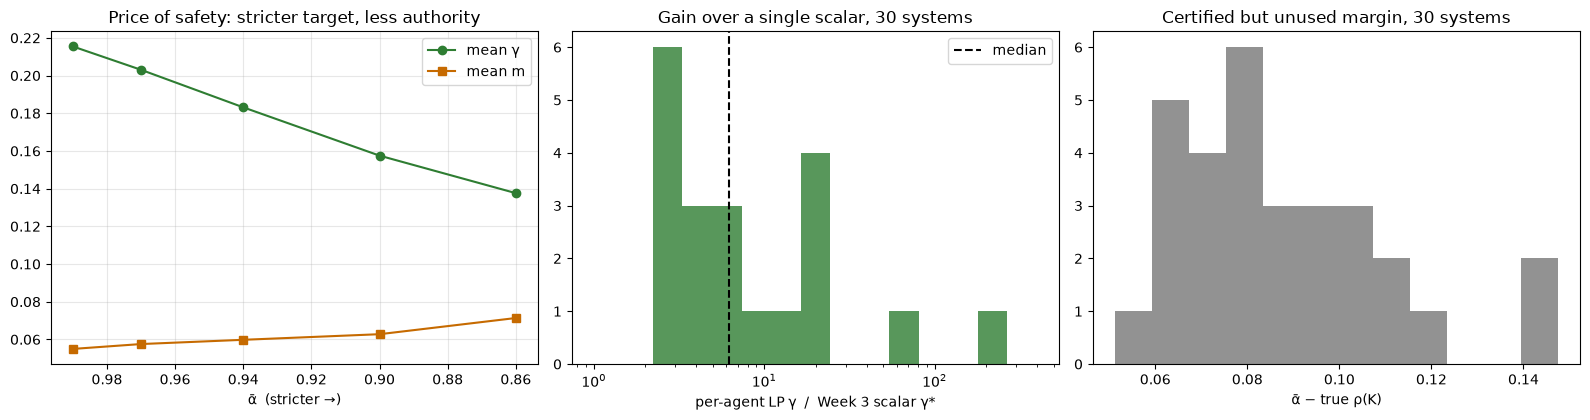

In [11]:
DEFAULT = dict(m=1.0, z_price=0.20, z_value=0.55, gamma=2.0)
SEED = 20260829

# Table 1: one system. W4.2 both ways: at Hadi's witness (anchored at m = 1) and re-anchored at m = 0
s = w4.make_system(SEED)
print(f"System {SEED}: {s['n_p']} sectors, {s['n_a']} agents, {s['n_e']} candidate links, "
      f"{s['n_p'] + s['n_e'] + s['n_a']} variables, {s['n_p'] + s['n_a']} row constraints\n")
print(f"{'witness anchor':<16}{'design':<22}{'mean m':>8}{'links on':>10}{'mean γ':>9}{'ρ(K)':>8}")
for m_anchor in [1.0, 0.0]:
    v = witness_at(s, m_anchor, 0.94)
    for name, cost, fix in [("default LP", DEFAULT, False),
                            ("value of γ = 0.5", {**DEFAULT, "gamma": 0.5}, False),
                            ("m fixed at 0", DEFAULT, True)]:
        sol = solve(s, v, 0.94, cost, fix)
        if sol is None:
            print(f"{f'm = {m_anchor:.0f}':<16}{name:<22}  infeasible"); continue
        K = w4.assemble(s, sol["m"], sol["z"], sol["g"])
        print(f"{f'm = {m_anchor:.0f}':<16}{name:<22}{sol['m'].mean():>8.4f}{int((sol['z'] > .5).sum()):>10}"
              f"{sol['g'].mean():>9.4f}{w4.rho(K):>8.4f}")
v = w4.fallback_witness(s)   # Hadi's witness, used by the tables below

# Table 2: price of safety (Hadi's Part D)
targets = [0.99, 0.97, 0.94, 0.90, 0.86]
pos = []
for ab in targets:
    sol = w4.solve_joint(s, w4.fallback_witness(s, alpha=min(ab, .995)), alpha_bar=ab)
    pos.append((ab, sol["m"].mean(), int((sol["z"] > .5).sum()), sol["g"].mean()))
print(f"\n{'ᾱ':>6}{'mean m':>9}{'links on':>10}{'mean γ':>9}")
for ab, m, l, g in pos: print(f"{ab:>6.2f}{m:>9.4f}{l:>10}{g:>9.4f}")

# Table 3: 30 systems
recs = []
for k in range(30):
    sk = w4.make_system(SEED + k); vk = w4.fallback_witness(sk); sol = w4.solve_joint(sk, vk)
    K = w4.assemble(sk, sol["m"], sol["z"], sol["g"])
    g3 = w4.week3_gamma_star(sk, vk, sol["m"], sol["z"])
    recs.append(dict(g=sol["g"].mean(), ratio=sol["g"].mean()/g3 if g3 > 1e-9 else np.nan,
                     links=int((sol["z"] > .5).sum()), slack=float(np.max(K @ vk / vk)) - w4.rho(K)))
q = lambda key: np.nanpercentile([r[key] for r in recs], [25, 50, 75])
print("\n30 systems            median      IQR")
for key, lab in [("g", "mean γ admitted"), ("ratio", "× Week 3 scalar"), ("links", "links on"), ("slack", "unused margin")]:
    lo, med, hi = q(key); print(f"{lab:<20}{med:>9.4f}   [{lo:.4f}, {hi:.4f}]")

# Figures
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].plot([p[0] for p in pos], [p[3] for p in pos], "o-", color=GREEN, label="mean γ")
ax[0].plot([p[0] for p in pos], [p[1] for p in pos], "s-", color=ORANGE, label="mean m")
ax[0].invert_xaxis(); ax[0].set_xlabel("ᾱ  (stricter →)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title("Price of safety: stricter target, less authority")
ax[1].hist([r["ratio"] for r in recs], bins=np.logspace(0, 2.6, 16), color=GREEN, alpha=.8); ax[1].set_xscale("log")
ax[1].axvline(np.nanmedian([r["ratio"] for r in recs]), color="k", ls="--", label="median")
ax[1].set_xlabel("per-agent LP γ  /  Week 3 scalar γ*"); ax[1].legend()
ax[1].set_title("Gain over a single scalar, 30 systems")
ax[2].hist([r["slack"] for r in recs], bins=12, color=GRAY, alpha=.8)
ax[2].set_xlabel("ᾱ − true ρ(K)"); ax[2].set_title("Certified but unused margin, 30 systems")
plt.tight_layout(); plt.show()